##Dataset Preparation


In [1]:
#Janani K - 24BAD039

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Pixel range:", x_train.min(), "to", x_train.max())


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Pixel range: 0 to 255


In [2]:

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape images into one-dimensional vectors
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Use input data as target output
print("Training data after reshaping:", x_train.shape)
print("Testing data after reshaping:", x_test.shape)


Training data after reshaping: (60000, 784)
Testing data after reshaping: (10000, 784)


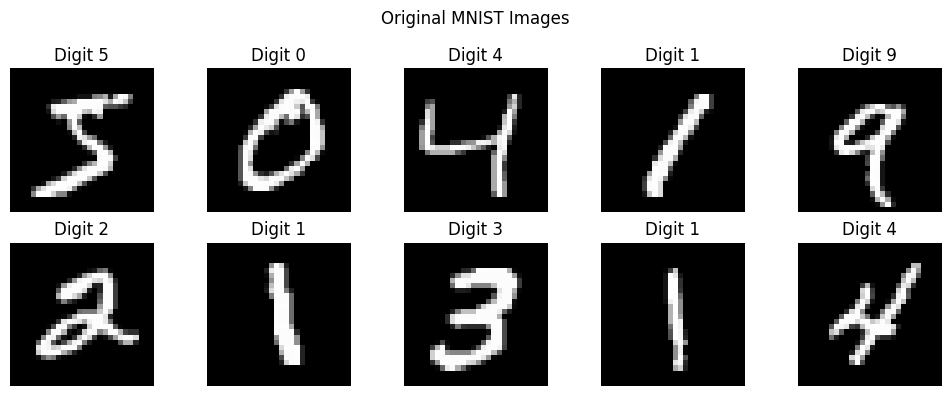

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Digit {y_train[i]}")
    plt.axis('off')

plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()


###Observation

The MNIST dataset was successfully loaded with 60,000 training images and 10,000 testing images. Each image had dimensions of 28 × 28 pixels and the original pixel values ranged from 0 to 255. The pixel values were normalized between 0 and 1, and the images were reshaped into 784-dimensional vectors.

##Implementing the Autoencoder Model

In [6]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Define input layer
input_layer = Input(shape=(784,))

# Encoder
encoder_layer1 = Dense(128, activation='relu')(input_layer)
encoder_layer2 = Dense(64, activation='relu')(encoder_layer1)

# Bottleneck layer
bottleneck = Dense(32, activation='relu')(encoder_layer2)

# Decoder
decoder_layer1 = Dense(64, activation='relu')(bottleneck)
decoder_layer2 = Dense(128, activation='relu')(decoder_layer1)

# Output layer
output_layer = Dense(784, activation='sigmoid')(decoder_layer2)

# Complete Autoencoder
autoencoder = Model(input_layer, output_layer)

# Separate Encoder model
encoder = Model(input_layer, bottleneck)

# Compile the Autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

# Display model summary
autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
encoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

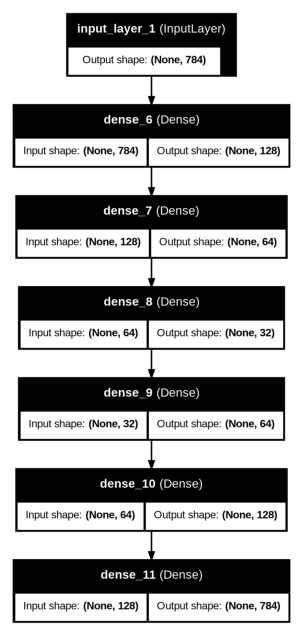

In [8]:
from tensorflow.keras.utils import plot_model

plot_model(
    autoencoder,
    show_shapes=True,
    show_layer_names=True,
    to_file='autoencoder_architecture.png'
)

plt.figure(figsize=(12, 8))
img = plt.imread('autoencoder_architecture.png')
plt.imshow(img)
plt.axis('off')
plt.show()

### Observation

The Autoencoder was successfully constructed with an Encoder, Bottleneck and Decoder. The input dimension of 784 was reduced to 32 neurons in the bottleneck layer. The model contained 222,384 trainable parameters. The model was compiled using the Adam optimizer and Mean Squared Error loss function.

##Model Training and Performance Evaluation

In [9]:
# Train the Autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 0.0633 - val_loss: 0.0354
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0298 - val_loss: 0.0249
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0226 - val_loss: 0.0204
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0198 - val_loss: 0.0187
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0179 - val_loss: 0.0168
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0165 - val_loss: 0.0160
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0155 - val_loss: 0.0148
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0147 - val_loss: 0.0140
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0140 - val_loss: 0.0134
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0134 - val_loss: 0.0127
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0127 - val_loss: 0.0122
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 

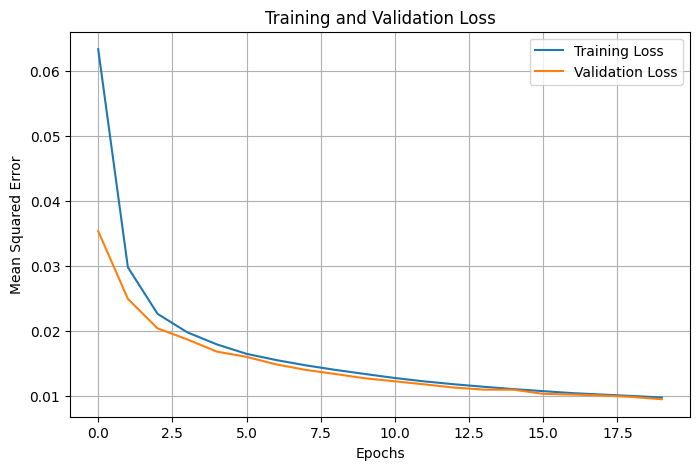

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)

print("Test Reconstruction MSE:", test_loss)

Test Reconstruction MSE: 0.0094836400821805


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step


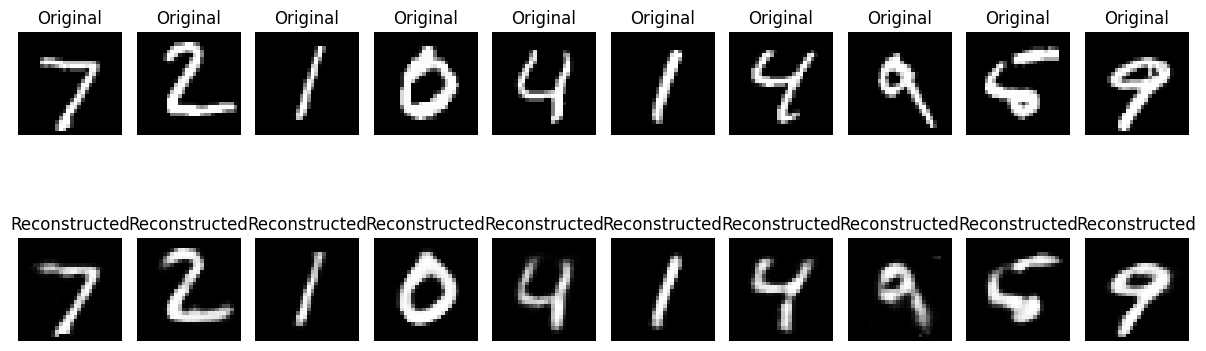

In [12]:
# Generate reconstructed images
reconstructed_images = autoencoder.predict(x_test[:10])

# Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Observation

The Autoencoder was successfully trained for 20 epochs. The training loss decreased from 0.0633 to 0.0097, while the validation loss decreased from 0.0354 to 0.0095. The test reconstruction MSE was 0.00948364. The decreasing loss values indicate that the model learned to reconstruct the input images effectively.

##Dimensionality Reduction, Feature Visualization and Experiment Management

In [13]:
# Extract compressed features
latent_features = encoder.predict(x_test)

print("Original data dimensions:", x_test.shape)
print("Compressed data dimensions:", latent_features.shape)

print("\nSample latent representation:")
print(latent_features[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Original data dimensions: (10000, 784)
Compressed data dimensions: (10000, 32)

Sample latent representation:
[ 0.         0.        15.289322   8.317519  10.540307   8.095671
 16.820509   9.505918  10.755139   4.889948   0.        17.899271
  4.738395   4.450556   5.9198384  4.7634883 11.921591   8.389682
 10.954418  11.684986   4.420875   8.245609  12.085202  13.197937
 13.2571945  9.201308  14.206167  11.127933   9.639027   9.118167
  0.        14.300336 ]


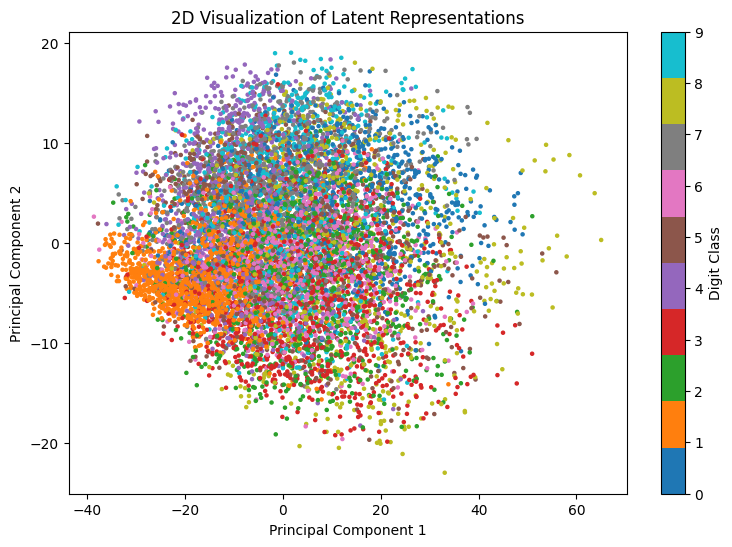

In [14]:
from sklearn.decomposition import PCA

# Reduce 32-dimensional features to 2 dimensions
pca = PCA(n_components=2)

latent_2d = pca.fit_transform(latent_features)

# Visualize latent representations
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter, label='Digit Class')
plt.title('2D Visualization of Latent Representations')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


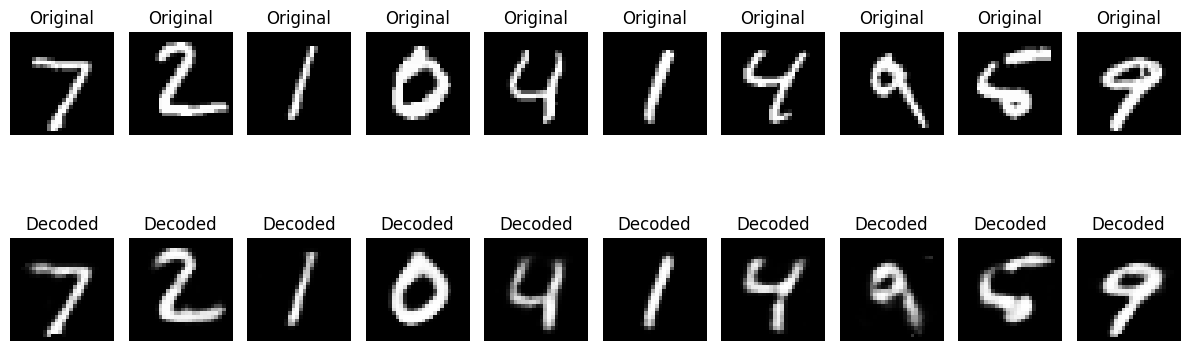

In [15]:
# Create a separate Decoder
decoder_input = Input(shape=(32,))

# Reuse the trained Decoder layers
d1 = autoencoder.layers[4](decoder_input)
d2 = autoencoder.layers[5](d1)
decoder_output = autoencoder.layers[6](d2)

decoder = Model(decoder_input, decoder_output)

# Encode selected test samples
encoded_data = encoder.predict(x_test[:10])

# Decode the compressed representations
decoded_data = decoder.predict(encoded_data)

# Display original and decoded images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_data[i].reshape(28, 28), cmap='gray')
    plt.title("Decoded")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [16]:
import pandas as pd

# Save latent features into a CSV file
latent_df = pd.DataFrame(latent_features)

latent_df['Digit_Label'] = y_test

latent_df.to_csv('latent_features.csv', index=False)

print("Latent representations saved successfully!")

Latent representations saved successfully!


In [17]:
autoencoder.save('mnist_autoencoder.keras')

print("Autoencoder model saved successfully!")

Autoencoder model saved successfully!


### Observation

The trained Encoder successfully compressed the test data from 784 dimensions to 32 dimensions. The compressed representations achieved a dimensionality reduction of 95.92%. PCA was used to visualize the latent representations in two dimensions. The visualization showed overlapping distributions among different digit classes with some visible groupings. The Decoder was used to reconstruct images from their compressed representations.